# Data analysis and fixed split

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from matplotlib.patches import Patch, Rectangle
from IPython.display import display

ROOT = Path.cwd() if Path("src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import export_yolo, ignore_mask, index_annotations, load, select_frames

DATA = ROOT / "data/raw"
RESULTS = ROOT / "results"
FIGURES = ROOT / "images"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
cocos = {split: load(DATA / split / "annotations_coco.json") for split in ["train", "val"]}
names = {c["id"]: c["name"] for c in cocos["train"]["categories"]}

## Class balance, sizes, and scene density

In [2]:
frame_tables, object_tables, ignore_tables = [], [], []
for split, coco in cocos.items():
    frames = pd.DataFrame(coco["images"])
    labels = pd.DataFrame(coco["annotations"])
    objects = labels.loc[labels.iscrowd.eq(0), ["image_id", "category_id", "bbox", "area", "occlusion", "track_id"]].copy()
    boxes = np.array(objects.bbox.tolist())
    objects[["x", "y", "w", "h"]] = boxes
    objects["class"] = objects.category_id.map(names)
    objects = objects.merge(frames[["id", "video", "width", "height"]], left_on="image_id", right_on="id", validate="many_to_one")
    objects["split"] = split
    frames["objects"] = frames.id.map(objects.groupby("image_id").size()).fillna(0).astype(int)
    frames["split"] = split
    ignores = labels.loc[labels.iscrowd.eq(1)].assign(box=lambda d: d.bbox.map(tuple)).drop_duplicates(["image_id", "box"])
    ignores["split"] = split
    frame_tables.append(frames)
    object_tables.append(objects.drop(columns=["bbox"]))
    ignore_tables.append(ignores)
frames = pd.concat(frame_tables, ignore_index=True)
objects = pd.concat(object_tables, ignore_index=True)
ignores = pd.concat(ignore_tables, ignore_index=True)
classes = objects.groupby(["split", "class"]).size().unstack(0).reindex(names.values())
classes.to_csv(RESULTS / "class_counts.csv")
summary = frames.groupby("split").agg(clips=("video", "nunique"), frames=("id", "size"), objects=("objects", "sum"),
                                        mean_objects=("objects", "mean"), median_objects=("objects", "median"), max_objects=("objects", "max"))
summary["ignore_regions"] = ignores.groupby("split").size()
summary["small_fraction"] = objects.assign(small=objects.area.lt(32**2)).groupby("split").small.mean()
summary.to_csv(RESULTS / "data_summary.csv")
clip_stats = frames.groupby(["split", "video"]).agg(frames=("id", "size"), mean_objects=("objects", "mean"), max_objects=("objects", "max"))
clip_stats["small_fraction"] = objects.assign(small=objects.area.lt(32**2)).groupby(["split", "video"]).small.mean()
clip_stats.to_csv(RESULTS / "clip_stats.csv")
objects.groupby(["split", "video", "class"]).size().unstack(fill_value=0).to_csv(RESULTS / "clip_class_counts.csv")
objects.groupby(["split", "class"])[["w", "h", "area"]].quantile([0.1, 0.5, 0.9]).to_csv(RESULTS / "box_quantiles.csv")
display(summary.round(3))
display(classes)

,clips,frames,objects,mean_objects,median_objects,max_objects,ignore_regions,small_fraction
split,,,,,,,,
train,56,24201,1105516,45.681,43.0,180,63843,0.249
val,7,2846,114132,40.103,37.0,116,3995,0.192


split,train,val
class,,
person,328701,50312
bicycle,40255,6022
car,505301,31821
van,46940,6842
truck,30498,1359
tricycle,41349,5487
bus,9653,264
motor,102819,12025


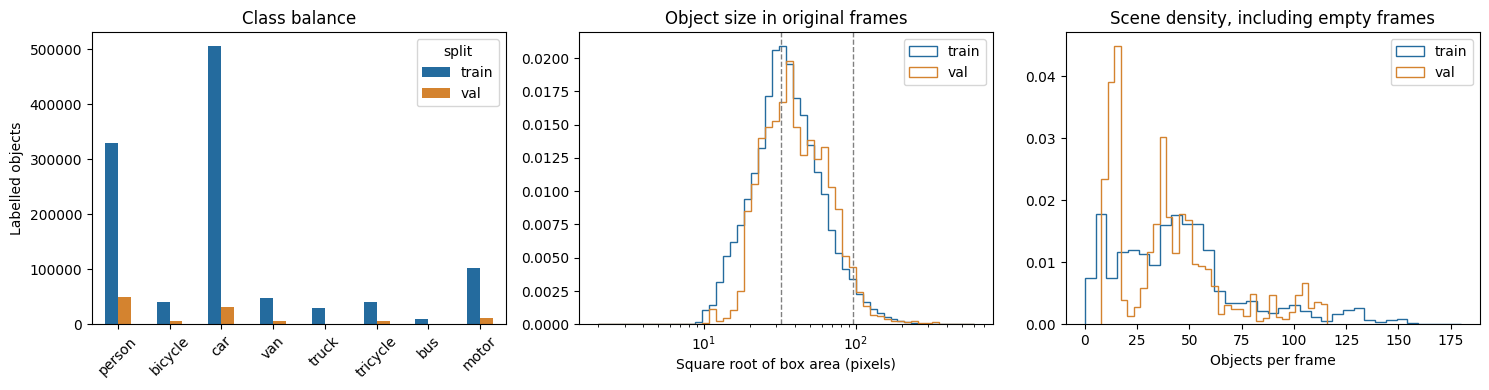

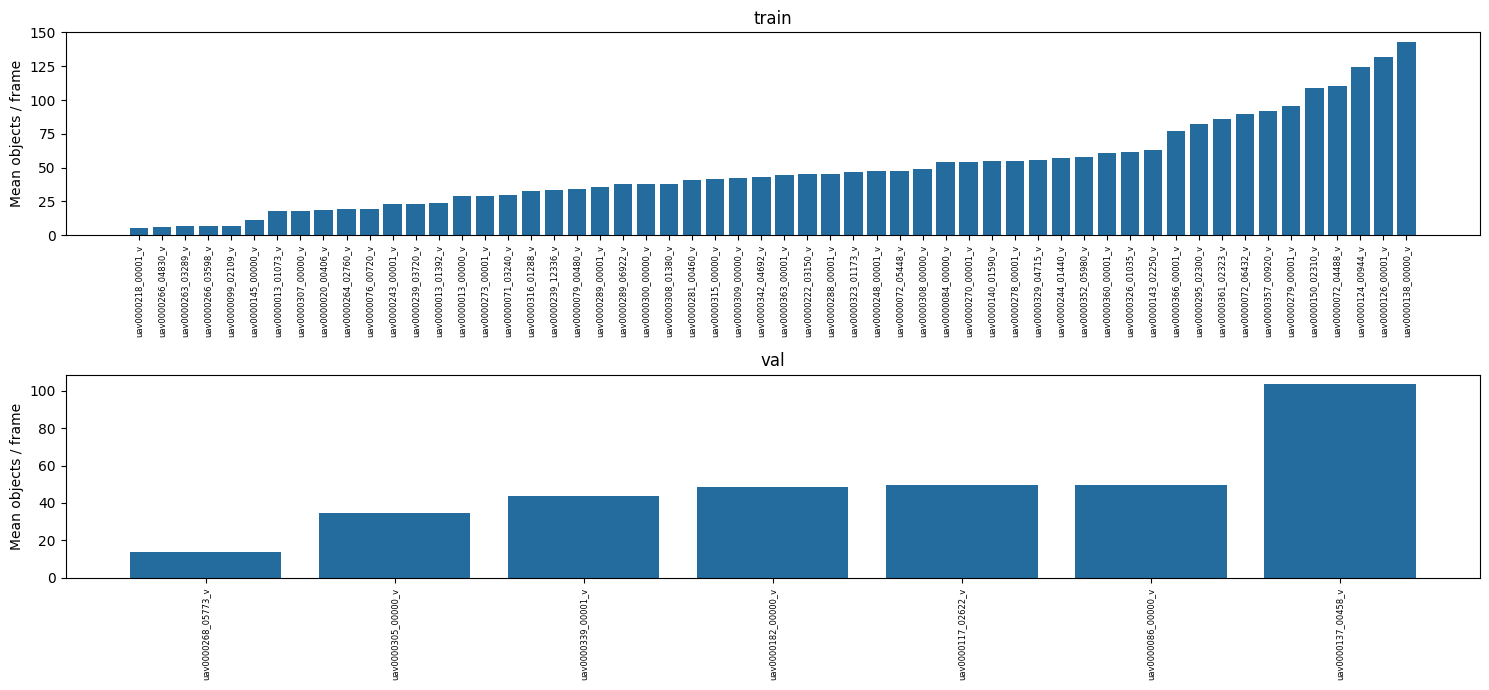

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
classes.plot.bar(ax=axes[0], rot=45, color=["#246b9e", "#d4832f"])
axes[0].set_ylabel("Labelled objects")
axes[0].set_xlabel("")
axes[0].set_title("Class balance")
for split, color in [("train", "#246b9e"), ("val", "#d4832f")]:
    area = objects.loc[objects.split.eq(split), "area"]
    axes[1].hist(np.sqrt(area), bins=np.geomspace(2, 600, 55), density=True, histtype="step", label=split, color=color)
    axes[2].hist(frames.loc[frames.split.eq(split), "objects"], bins=35, density=True, histtype="step", label=split, color=color)
axes[1].set_xscale("log")
axes[1].axvline(32, color="grey", ls="--", lw=1)
axes[1].axvline(96, color="grey", ls="--", lw=1)
axes[1].set_xlabel("Square root of box area (pixels)")
axes[1].set_title("Object size in original frames")
axes[2].set_xlabel("Objects per frame")
axes[2].set_title("Scene density, including empty frames")
for ax in axes[1:]:
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "data_distributions.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(15, 7))
for ax, split in zip(axes, ["train", "val"]):
    values = clip_stats.loc[split].sort_values("mean_objects")
    ax.bar(values.index, values.mean_objects, color="#246b9e")
    ax.set_ylabel("Mean objects / frame")
    ax.set_title(split)
    ax.tick_params(axis="x", rotation=90, labelsize=6)
fig.tight_layout()
fig.savefig(FIGURES / "clip_density.png", dpi=160)
plt.show()

## Fixed clip split and frame-stride audit

Training uses every fifth frame of each clip; validation uses every frame. The accuracy effect of subsampling remains to be measured.

In [4]:
train_clips = sorted({i["video"] for i in cocos["train"]["images"]})
val_clips = sorted({i["video"] for i in cocos["val"]["images"]})
manifest = {"seed": SEED, "train_stride": 5, "val_stride": 1, "train_clips": train_clips, "val_clips": val_clips,
            "train_frames": len(select_frames(cocos["train"], 5)), "val_frames": len(cocos["val"]["images"]),
            "annotation_sha256": {s: hashlib.sha256((DATA / s / "annotations_coco.json").read_bytes()).hexdigest() for s in cocos},
            "metric": "COCO AP@[.5:.95]", "max_detections": 500, "ignore": "supplied per-class iscrowd annotations"}
(RESULTS / "split.json").write_text(json.dumps(manifest, indent=2) + "\n")
audit = []
train_objects = objects.loc[objects.split.eq("train")]
for stride in [1, 5, 10]:
    selected = select_frames(cocos["train"], stride)
    sampled = train_objects.loc[train_objects.image_id.isin({i["id"] for i in selected})]
    row = {"stride": stride, "frames": len(selected), "objects": len(sampled),
           "tracks": sampled[["video", "track_id"]].drop_duplicates().shape[0]}
    row.update(sampled["class"].value_counts().reindex(names.values(), fill_value=0).to_dict())
    audit.append(row)
audit = pd.DataFrame(audit)
audit.to_csv(RESULTS / "stride_audit.csv", index=False)
display(audit)
print(f"Fixed split: {manifest['train_frames']} train frames, {manifest['val_frames']} validation frames")

,stride,frames,objects,tracks,person,bicycle,car,van,truck,tricycle,bus,motor
0,1,24201,1105516,7342,328701,40255,505301,46940,30498,41349,9653,102819
1,5,4868,222879,7288,66353,8129,101814,9452,6137,8337,1945,20712
2,10,2446,112264,7239,33493,4109,51186,4762,3097,4197,983,10437


Fixed split: 4868 train frames, 2846 validation frames


## Ground-truth boxes

Samples cover ordinary, crowded, and rare-class scenes. Coloured boxes are targets; grey boxes are unique ignore regions.

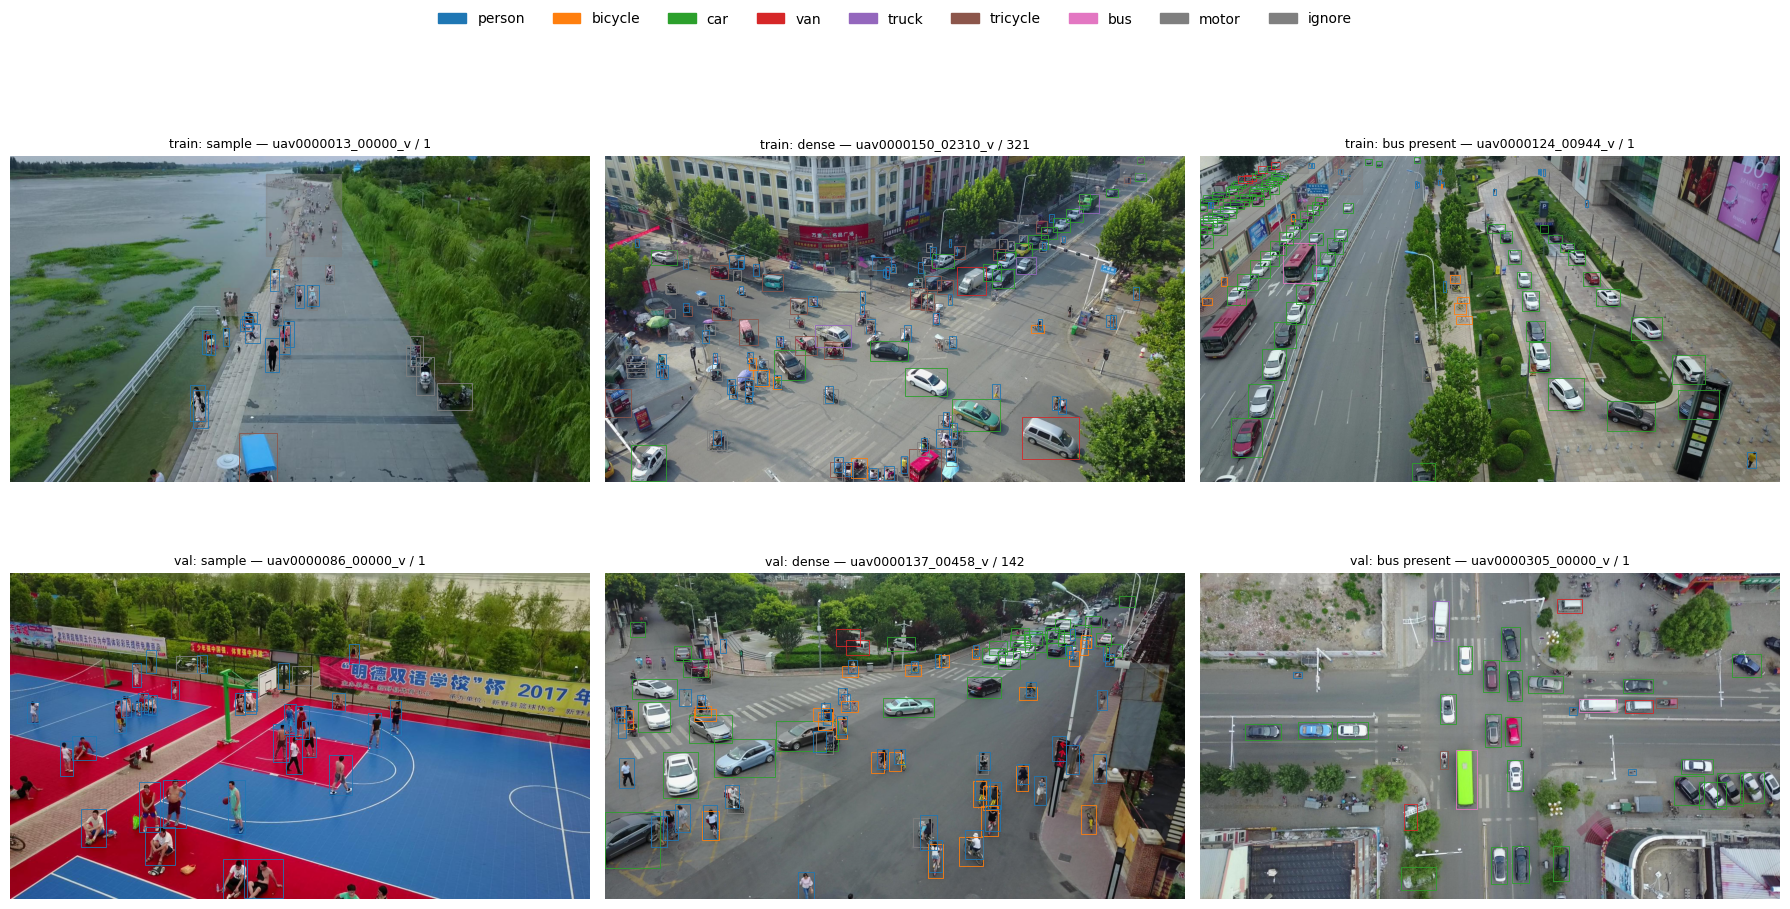

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
colors = plt.get_cmap("tab10")
for row, split in enumerate(["train", "val"]):
    coco = cocos[split]
    annotation_index = index_annotations(coco)
    available = [i for i in select_frames(coco, 5 if split == "train" else 1)
                 if (DATA / split / i["file_name"]).exists()]
    by_id = {i["id"]: i for i in available}
    density = frames.loc[frames.split.eq(split) & frames.id.isin(by_id)].set_index("id").objects
    rare = objects.loc[objects.split.eq(split) & objects.category_id.eq(7) & objects.image_id.isin(by_id)].image_id.iloc[0]
    chosen = [available[0], by_id[density.idxmax()], by_id[rare]]
    for ax, image, label in zip(axes[row], chosen, ["sample", "dense", "bus present"]):
        with Image.open(DATA / split / image["file_name"]) as source:
            ax.imshow(source)
        annotations = annotation_index[image["id"]]
        for a in annotations:
            if not a["iscrowd"]:
                x, y, w, h = a["bbox"]
                ax.add_patch(Rectangle((x, y), w, h, fill=False, color=colors(a["category_id"] - 1), lw=0.6))
        for x, y, w, h in {tuple(a["bbox"]) for a in annotations if a["iscrowd"]}:
            ax.add_patch(Rectangle((x, y), w, h, color="grey", alpha=0.4))
        ax.set_title(f"{split}: {label} — {image['video']} / {image['frame_id']}", fontsize=9)
        ax.axis("off")
fig.legend(handles=[Patch(color=colors(c - 1), label=name) for c, name in names.items()]
           + [Patch(color="grey", label="ignore")], loc="upper center", ncol=9, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGURES / "ground_truth.png", dpi=160)
plt.show()

## COCO and YOLO label consistency

Boxes rebuilt from the normalised YOLO labels are drawn over the exported image (grey = ignore regions). Boxes more than half inside an ignore region are dropped from the labels.

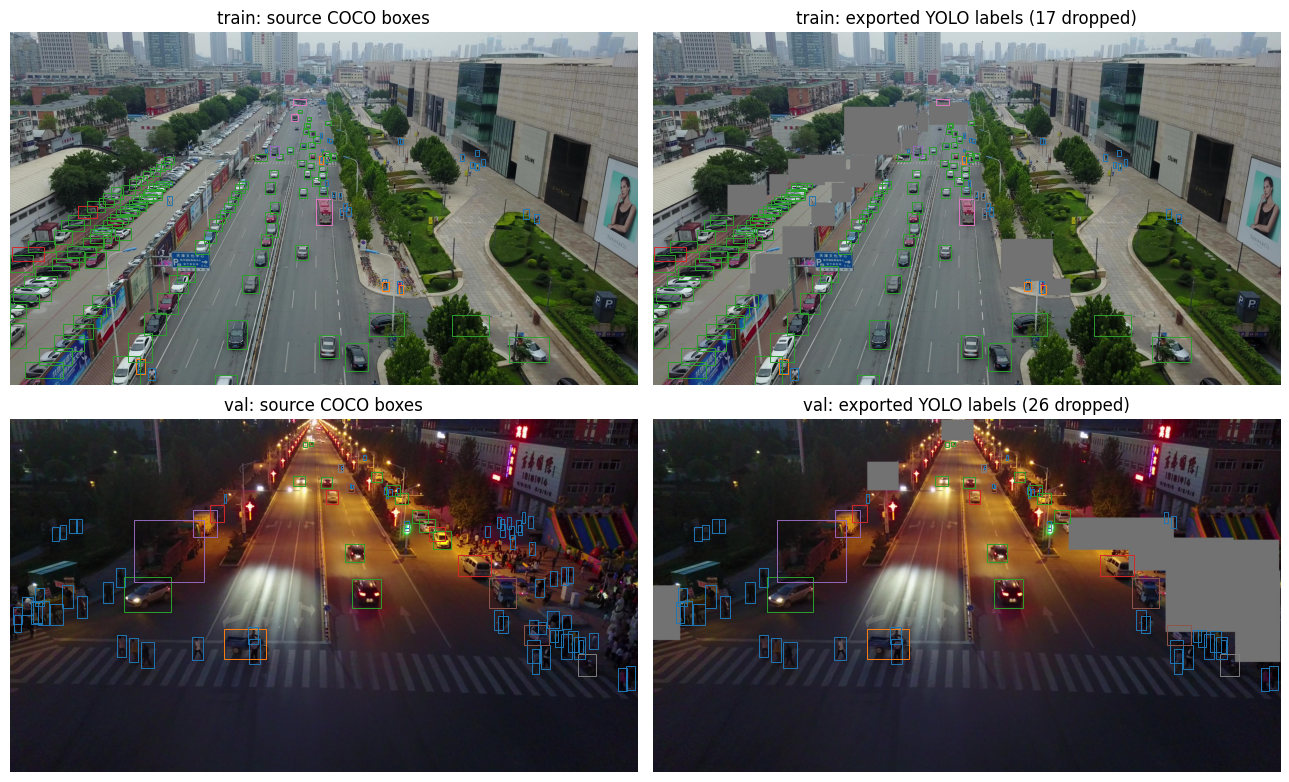

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
preview = ROOT / "data/preview"
for row, split in enumerate(["train", "val"]):
    coco = cocos[split]
    image = max(select_frames(coco, 50), key=lambda i: sum(a["iscrowd"] for a in index_annotations(coco)[i["id"]]))
    export_yolo({**coco, "images": [image]}, DATA / split, preview, split, 1, 10_000)
    name = f'{image["video"]}_{Path(image["file_name"]).stem}'
    W, H = image["width"], image["height"]
    labels = np.loadtxt(preview / "labels" / split / f"{name}.txt", ndmin=2)
    rebuilt = np.c_[(labels[:, 1] - labels[:, 3] / 2) * W, (labels[:, 2] - labels[:, 4] / 2) * H, labels[:, 3] * W, labels[:, 4] * H]
    annotations = [a for a in index_annotations(coco)[image["id"]] if not a["iscrowd"]]
    mask = ignore_mask(image, index_annotations(coco)[image["id"]])
    kept = [a for a in annotations if mask[int(a["bbox"][1]):int(np.ceil(a["bbox"][1] + a["bbox"][3])), int(a["bbox"][0]):int(np.ceil(a["bbox"][0] + a["bbox"][2]))].mean() <= 0.5]
    np.testing.assert_allclose(rebuilt, [a["bbox"] for a in kept], atol=0.01)
    panels = [(DATA / split / image["file_name"], [a["bbox"] for a in annotations], [a["category_id"] - 1 for a in annotations], "source COCO boxes"),
              (preview / "images" / split / f"{name}.jpg", rebuilt, labels[:, 0].astype(int), f"exported YOLO labels ({len(annotations) - len(kept)} dropped)")]
    for ax, (path, boxes, classes, title) in zip(axes[row], panels):
        ax.imshow(Image.open(path))
        for (x, y, w, h), c in zip(boxes, classes):
            ax.add_patch(Rectangle((x, y), w, h, fill=False, color=colors(c), lw=0.7))
        ax.set_title(f"{split}: {title}")
        ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "yolo_conversion.png", dpi=160)
plt.show()
